# Phytochemical-Protein Interaction Prediction

## Task and reasoning

The primary task is to rank candidate human protein targets for each phytochemical using curated compound-protein associations as known positives. The available interaction table contains positives only: pairs absent from it are **unlabeled, not confirmed non-interactions**. Consequently, classifiers below are PU baselines trained against sampled unlabeled pairs, and reported metrics describe recovery of held-out curated positives against that sampled background, not calibrated biological truth.

We first inspect the feature and label distributions, validate join keys and AAC normalization, then compare three classical PU baselines and a heterogeneous random walk. The default split holds out interaction edges while keeping compounds and proteins in the node universe. A cold-compound split utility is included for unseen-compound evaluation. Random walk uses training positives only to avoid leaking held-out interaction edges.

## Dataset guide

- **Compound features:** 2,319 compounds represented by 2,048 binary ECFP4/Morgan radius-2 bits.
- **Target features:** 1,341 reviewed human proteins represented by 20 normalized amino-acid-composition (AAC) values, plus identifiers and names.
- **Known interactions:** 14,166 unique curated compound-protein pairs, all labeled positive.
- **Unlabeled universe:** 3,095,613 remaining pairs from the full compound x protein product; these are unmeasured/unrecorded, not negatives.
- **Herb-compound edges:** IMPPAT plant-to-compound associations, used to extend the compound-target graph for random walks.
- **Herb-compound-target paths:** Derived multi-hop hypotheses, not direct evidence that a herb engages a target in vivo.

Pair-model inputs concatenate compound ECFP4 and protein AAC features (2,068 values per pair). Their dimensions differ, so an elementwise product is undefined; concatenation is the transparent baseline.

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

DATASET_PATH = Path("datasets/imppat_hti_aac_ecfp4_v1")

compound_features = pd.read_csv(DATASET_PATH / "compound_features_ecfp4.csv")
target_features = pd.read_csv(DATASET_PATH / "target_features_aac.csv")
positive_pairs = pd.read_csv(DATASET_PATH / "compound_target_labeled.csv")
herb_compound_edges = pd.read_csv(DATASET_PATH / "herb_compound_edges.tsv", sep="\t")
herb_compound_target = pd.read_csv(DATASET_PATH / "herb_compound_target.csv")

fingerprint_columns = [column for column in compound_features if column.startswith("ecfp4_")]
aac_columns = [column for column in target_features if column.startswith("aac_")]

print("Loaded rows:")
display(pd.Series({
    "compounds": len(compound_features),
    "targets": len(target_features),
    "known positive pairs": len(positive_pairs),
    "herb-compound edges": len(herb_compound_edges),
    "herb-compound-target paths": len(herb_compound_target),
}, name="rows").to_frame())
print(f"Features per pair: {len(fingerprint_columns)} ECFP4 + {len(aac_columns)} AAC")

Loaded rows:


,rows
compounds,2319
targets,1341
known positive pairs,14166
herb-compound edges,8396
herb-compound-target paths,126830


Features per pair: 2048 ECFP4 + 20 AAC


## Exploratory data analysis

Before fitting models, check identifiers, missingness, class semantics, feature ranges, and interaction-degree imbalance. The plots below summarize fingerprint sparsity, amino-acid composition, and positive interaction degrees.

In [27]:
# Basic schema, key, label, and feature-integrity checks.
summary = pd.DataFrame({
    "rows": [len(compound_features), len(target_features), len(positive_pairs)],
    "columns": [compound_features.shape[1], target_features.shape[1], positive_pairs.shape[1]],
    "duplicate primary keys": [
        compound_features["compound_id"].duplicated().sum(),
        target_features["protein_id"].duplicated().sum(),
        positive_pairs[["compound_id", "protein_id"]].duplicated().sum(),
    ],
    "missing values": [
        int(compound_features.isna().sum().sum()),
        int(target_features.isna().sum().sum()),
        int(positive_pairs[["compound_id", "protein_id", "label"]].isna().sum().sum()),
    ],
}, index=["compound features", "target features", "known interactions"])
display(summary)

print("Positive labels:", positive_pairs["label"].value_counts().to_dict())
print("Positive status:", positive_pairs["label_status"].value_counts().to_dict())
print("Compound IDs missing from features:", (~positive_pairs["compound_id"].isin(compound_features["compound_id"])).sum())
print("Protein IDs missing from features:", (~positive_pairs["protein_id"].isin(target_features["protein_id"])).sum())
print("AAC row-sum range:", target_features[aac_columns].sum(axis=1).min(), target_features[aac_columns].sum(axis=1).max())
print("Mean fingerprint bits set per compound:", compound_features[fingerprint_columns].to_numpy(dtype=np.float32).sum(axis=1).mean())

,rows,columns,duplicate primary keys,missing values
compound features,2319,2049,0,0
target features,1341,23,0,0
known interactions,14166,15,0,0


Positive labels: {1: 14166}
Positive status: {'IMPPAT_ASSOCIATION': 14166}
Compound IDs missing from features: 0
Protein IDs missing from features: 0
AAC row-sum range: 0.9999999999999984 1.0000000000000002
Mean fingerprint bits set per compound: 37.949978


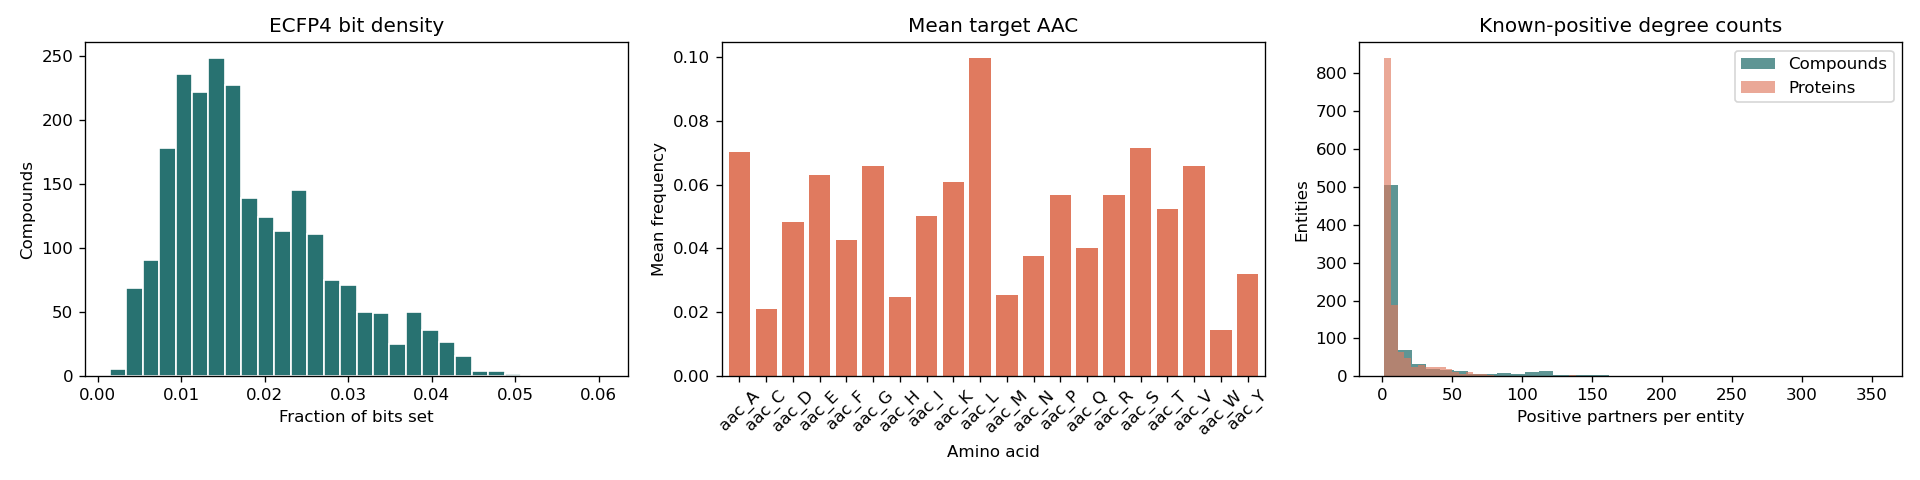

Positive interactions per compound (median/max): 5.0 354
Positive interactions per protein (median/max): 3.0 173
EDA note: these degrees describe recorded evidence, not biological selectivity or inactivity.


In [28]:
# EDA plots: fingerprints are sparse binary features; AAC rows are compositions.
from io import BytesIO
from IPython.display import Image
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure

fig = Figure(figsize=(16, 4))
FigureCanvasAgg(fig)
axes = fig.subplots(1, 3)

fingerprint_density = compound_features[fingerprint_columns].mean(axis=1)
axes[0].hist(fingerprint_density, bins=30, color="#287271", edgecolor="white")
axes[0].set(title="ECFP4 bit density", xlabel="Fraction of bits set", ylabel="Compounds")

target_features[aac_columns].mean().plot(kind="bar", ax=axes[1], color="#e07a5f", width=0.8)
axes[1].set(title="Mean target AAC", xlabel="Amino acid", ylabel="Mean frequency")
axes[1].tick_params(axis="x", rotation=45)

compound_degree = positive_pairs.groupby("compound_id").size()
protein_degree = positive_pairs.groupby("protein_id").size()
axes[2].hist(compound_degree, bins=35, alpha=0.75, label="Compounds", color="#287271")
axes[2].hist(protein_degree, bins=35, alpha=0.65, label="Proteins", color="#e07a5f")
axes[2].set(title="Known-positive degree counts", xlabel="Positive partners per entity", ylabel="Entities")
axes[2].legend()
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=120)
display(Image(data=image_buffer.getvalue()))

print("Positive interactions per compound (median/max):", compound_degree.median(), compound_degree.max())
print("Positive interactions per protein (median/max):", protein_degree.median(), protein_degree.max())
print("EDA note: these degrees describe recorded evidence, not biological selectivity or inactivity.")

## Splits, candidate sampling, and metrics

The default evaluation is transductive: split known positive edges into 70% train, 15% validation, and 15% test while retaining the fixed compound/protein universe. For cold-compound evaluation, all edges for a held-out compound stay together. Unlabeled candidates are sampled per compound at configurable ratios and streamed from disk; they are background examples only, never verified negatives.

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.ensemble import IsolationForest
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

SEED = 42
TRAIN_UNLABELED_PER_POSITIVE = 1
VALIDATION_UNLABELED_PER_POSITIVE = 10
TEST_UNLABELED_PER_POSITIVE = 50
UNLABELED_PATH = DATASET_PATH / "compound_target_unlabeled.csv"

compound_ids = compound_features["compound_id"].to_numpy()
protein_ids = target_features["protein_id"].to_numpy()
compound_feature_matrix = compound_features.set_index("compound_id")[fingerprint_columns].astype(np.float32)
target_feature_matrix = target_features.set_index("protein_id")[aac_columns].astype(np.float32)


def split_positive_edges(pairs=positive_pairs, strategy="edge", random_state=SEED):
    """Return train/validation/test positives without splitting duplicate pairs."""
    if strategy == "edge":
        train, remainder = train_test_split(pairs, test_size=0.30, random_state=random_state)
        validation, test = train_test_split(remainder, test_size=0.50, random_state=random_state)
    elif strategy == "cold_compound":
        compounds = pairs["compound_id"].drop_duplicates().to_numpy()
        train_compounds, remainder = train_test_split(compounds, test_size=0.30, random_state=random_state)
        validation_compounds, test_compounds = train_test_split(remainder, test_size=0.50, random_state=random_state)
        train = pairs[pairs["compound_id"].isin(train_compounds)]
        validation = pairs[pairs["compound_id"].isin(validation_compounds)]
        test = pairs[pairs["compound_id"].isin(test_compounds)]
    else:
        raise ValueError("strategy must be 'edge' or 'cold_compound'")
    return tuple(part.reset_index(drop=True) for part in (train, validation, test))


def sample_unlabeled_by_compound(positive_reference, ratio, random_state=SEED, chunksize=200_000):
    """Uniformly reservoir-sample unlabeled pairs per compound from the CSV stream."""
    positives_per_compound = positive_reference.groupby("compound_id").size()
    caps = (positives_per_compound * ratio).clip(lower=1).astype(int).to_dict()
    reservoirs = {}
    rng = np.random.default_rng(random_state)
    for chunk in pd.read_csv(UNLABELED_PATH, usecols=["compound_id", "protein_id"], chunksize=chunksize):
        chunk = chunk[chunk["compound_id"].isin(caps)].copy()
        if chunk.empty:
            continue
        chunk["_priority"] = rng.random(len(chunk))
        for compound_id, group in chunk.groupby("compound_id", sort=False):
            combined = group
            if compound_id in reservoirs:
                combined = pd.concat([reservoirs[compound_id], group], ignore_index=True)
            reservoirs[compound_id] = combined.nlargest(caps[compound_id], "_priority")
    if not reservoirs:
        return pd.DataFrame(columns=["compound_id", "protein_id"])
    sampled = pd.concat(reservoirs.values(), ignore_index=True)
    return sampled[["compound_id", "protein_id"]].reset_index(drop=True)


def make_pair_features(pairs):
    """Concatenate ECFP4 and AAC vectors in pair-row order."""
    compounds = compound_feature_matrix.loc[pairs["compound_id"]].to_numpy(dtype=np.float32, copy=True)
    proteins = target_feature_matrix.loc[pairs["protein_id"]].to_numpy(dtype=np.float32, copy=True)
    return np.concatenate([compounds, proteins], axis=1)


def ranking_metrics(candidates, scores, ks=(10, 50)):
    """Report AP and per-compound Hits@K/MRR within the sampled candidate sets."""
    candidates = candidates.reset_index(drop=True).copy()
    candidates["score"] = np.asarray(scores)
    average_precision = average_precision_score(candidates["label"], candidates["score"])
    reciprocal_ranks = []
    hits = {k: [] for k in ks}
    for _, group in candidates.groupby("compound_id", sort=False):
        ranked = group.sort_values("score", ascending=False)
        positive_ranks = np.flatnonzero(ranked["label"].to_numpy() == 1) + 1
        if len(positive_ranks):
            reciprocal_ranks.append(1.0 / positive_ranks[0])
            for k in ks:
                hits[k].append(float(np.any(positive_ranks <= k)))
    result = {"PR-AUC (average precision)": average_precision,
              "MRR": float(np.mean(reciprocal_ranks)) if reciprocal_ranks else np.nan}
    result.update({f"Hits@{k}": float(np.mean(values)) if values else np.nan for k, values in hits.items()})
    return result


train_positive, validation_positive, test_positive = split_positive_edges(strategy="edge")
print("Edge split rows:", len(train_positive), len(validation_positive), len(test_positive))
print("Cold-compound option:", [len(part) for part in split_positive_edges(strategy="cold_compound")])

Edge split rows: 9916 2125 2125
Cold-compound option: [9704, 2777, 1685]


In [30]:
# Set to "cold_compound" to evaluate on compounds whose positive edges are all held out.
SPLIT_STRATEGY = "edge"  # choices: "edge" or "cold_compound"
train_positive, validation_positive, test_positive = split_positive_edges(strategy=SPLIT_STRATEGY)
print(f"Selected split: {SPLIT_STRATEGY}")
print("Train/validation/test positive pairs:", len(train_positive), len(validation_positive), len(test_positive))

cold_train, cold_validation, cold_test = split_positive_edges(strategy="cold_compound")
cold_sets = [set(part["compound_id"]) for part in (cold_train, cold_validation, cold_test)]
assert not (cold_sets[0] & cold_sets[1] or cold_sets[0] & cold_sets[2] or cold_sets[1] & cold_sets[2])
print("Cold-compound split sizes:", [len(part) for part in (cold_train, cold_validation, cold_test)])
print("Cold-compound entity partitions are disjoint: True")

Selected split: edge
Train/validation/test positive pairs: 9916 2125 2125
Cold-compound split sizes: [9704, 2777, 1685]
Cold-compound entity partitions are disjoint: True


## Build train and evaluation candidate sets

A single streamed pass builds a per-compound reservoir large enough for the 1:50 test background. Validation and test backgrounds are then sampled separately and excluded from the training background. This bounds memory and prevents the same unlabeled pair appearing on both sides of the evaluation split.

In [31]:
def sample_background_from_pool(positive_reference, ratio, rng, excluded_pairs=None):
    """Draw unlabeled candidates per compound, avoiding any reserved pairs."""
    excluded = set()
    if excluded_pairs is not None and not excluded_pairs.empty:
        excluded = set(map(tuple, excluded_pairs[["compound_id", "protein_id"]].to_numpy()))
    sampled = []
    for compound_id, positive_count in positive_reference.groupby("compound_id").size().items():
        available = unlabeled_by_compound.get(compound_id)
        if available is None:
            continue
        if excluded:
            mask = [(compound_id, protein_id) not in excluded for protein_id in available["protein_id"]]
            available = available.loc[mask]
        count = min(int(ratio * positive_count), len(available))
        if count:
            sampled.append(available.sample(n=count, random_state=int(rng.integers(0, 2**31 - 1))))
    if not sampled:
        return pd.DataFrame(columns=["compound_id", "protein_id"])
    return pd.concat(sampled, ignore_index=True)


def labeled_candidates(positives, background):
    positive_rows = positives[["compound_id", "protein_id"]].assign(label=1)
    background_rows = background[["compound_id", "protein_id"]].assign(label=0)
    return pd.concat([positive_rows, background_rows], ignore_index=True)


unlabeled_pool = sample_unlabeled_by_compound(
    positive_pairs, ratio=TEST_UNLABELED_PER_POSITIVE, random_state=SEED
)
unlabeled_by_compound = {
    compound_id: group[["compound_id", "protein_id"]].reset_index(drop=True)
    for compound_id, group in unlabeled_pool.groupby("compound_id", sort=False)
}
rng = np.random.default_rng(SEED)
train_background = sample_background_from_pool(train_positive, TRAIN_UNLABELED_PER_POSITIVE, rng)
validation_background = sample_background_from_pool(
    validation_positive, VALIDATION_UNLABELED_PER_POSITIVE, rng,
    excluded_pairs=train_background,
)
test_background = sample_background_from_pool(
    test_positive, TEST_UNLABELED_PER_POSITIVE, rng,
    excluded_pairs=pd.concat([train_background, validation_background], ignore_index=True),
)

train_candidates = labeled_candidates(train_positive, train_background)
validation_candidates = labeled_candidates(validation_positive, validation_background)
test_candidates = labeled_candidates(test_positive, test_background)

print("Positive/background candidates:")
print("train:", len(train_positive), len(train_background))
print("validation:", len(validation_positive), len(validation_background))
print("test:", len(test_positive), len(test_background))
train_test_overlap = len(set(map(tuple, train_background.to_numpy())) & set(map(tuple, test_background.to_numpy())))
print("Sampled unlabeled pair overlap (train/test):", train_test_overlap)
assert train_test_overlap == 0

Positive/background candidates:
train: 9916 9916
validation: 2125 21250
test: 2125 94433
Sampled unlabeled pair overlap (train/test): 0


## Classical PU baselines

The Isolation Forest uses only training-positive pair features to identify the most outlier-like candidates from a larger sampled training background; the bottom 20% become reliable-negative candidates, not ground-truth negatives. A tree classifier is iteratively refit after adding sampled candidates predicted below 0.01. XGBoost is used when installed; otherwise a scikit-learn histogram gradient-boosting model provides a compatible runnable baseline. Predictions are batched to keep peak memory bounded.

In [32]:
import gc
import importlib.util


def new_tree_classifier(random_state=SEED):
    if importlib.util.find_spec("xgboost") is not None:
        from xgboost import XGBClassifier
        return XGBClassifier(
            n_estimators=250, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, tree_method="hist",
            eval_metric="logloss", n_jobs=-1, random_state=random_state,
        )
    return HistGradientBoostingClassifier(
        max_iter=100, max_leaf_nodes=15, learning_rate=0.08,
        l2_regularization=1.0, random_state=random_state,
    )


def predict_positive_probability(model, pairs, batch_size=8192):
    probabilities = []
    for start in range(0, len(pairs), batch_size):
        batch = pairs.iloc[start:start + batch_size]
        probabilities.append(model.predict_proba(make_pair_features(batch))[:, 1])
    return np.concatenate(probabilities) if probabilities else np.array([])


# Step 1: find the low-support tail relative to the positive training feature space.
reliable_negative_pool = sample_background_from_pool(
    train_positive, ratio=5, rng=np.random.default_rng(SEED + 1),
    excluded_pairs=pd.concat([validation_background, test_background], ignore_index=True),
)
positive_feature_matrix = make_pair_features(train_positive)
reliable_pool_features = make_pair_features(reliable_negative_pool)
isolation_forest = IsolationForest(
    n_estimators=150, max_samples=min(256, len(positive_feature_matrix)),
    contamination="auto", random_state=SEED, n_jobs=-1,
)
isolation_forest.fit(positive_feature_matrix)
reliable_scores = isolation_forest.decision_function(reliable_pool_features)
reliable_cutoff = np.quantile(reliable_scores, 0.20)
reliable_negative_mask = reliable_scores <= reliable_cutoff
reliable_negatives = reliable_negative_pool.loc[reliable_negative_mask].reset_index(drop=True)

print("Tree backend:", "XGBoost" if importlib.util.find_spec("xgboost") else "HistGradientBoosting fallback")
print("Reliable-negative candidate count:", len(reliable_negatives), "of", len(reliable_negative_pool))
del reliable_pool_features, positive_feature_matrix, reliable_scores, isolation_forest
gc.collect()

# Steps 2-3: train on positives + reliable negatives, then expand from low-scoring candidates.
pu_train_pairs = pd.concat([train_positive, reliable_negatives], ignore_index=True)
pu_train_labels = np.r_[np.ones(len(train_positive)), np.zeros(len(reliable_negatives))]
pu_tree_model = new_tree_classifier()
pu_tree_model.fit(make_pair_features(pu_train_pairs), pu_train_labels)

remaining_background = reliable_negative_pool.loc[~reliable_negative_mask].reset_index(drop=True)
for iteration in range(2):
    remaining_scores = predict_positive_probability(pu_tree_model, remaining_background)
    expansion_mask = remaining_scores < 0.01
    newly_added = remaining_background.loc[expansion_mask].reset_index(drop=True)
    if newly_added.empty:
        print(f"Expansion {iteration + 1}: no candidates below 0.01; stopping.")
        break
    pu_train_pairs = pd.concat([pu_train_pairs, newly_added], ignore_index=True)
    pu_train_labels = np.r_[pu_train_labels, np.zeros(len(newly_added))]
    pu_tree_model = new_tree_classifier(random_state=SEED + iteration + 1)
    pu_tree_model.fit(make_pair_features(pu_train_pairs), pu_train_labels)
    remaining_background = remaining_background.loc[~expansion_mask].reset_index(drop=True)
    print(f"Expansion {iteration + 1}: added {len(newly_added)} sampled candidates.")

two_step_scores = predict_positive_probability(pu_tree_model, test_candidates)
two_step_metrics = ranking_metrics(test_candidates, two_step_scores)
print("Two-step PU held-out metrics:", two_step_metrics)

Tree backend: HistGradientBoosting fallback
Reliable-negative candidate count: 7176 of 35879
Expansion 1: no candidates below 0.01; stopping.
Two-step PU held-out metrics: {'PR-AUC (average precision)': 0.050065479771178284, 'MRR': 0.4405574443349856, 'Hits@10': 0.7434679334916865, 'Hits@50': 0.9881235154394299}


## Elkan-Noto calibration and cost-sensitive SVM

Elkan-Noto estimates the fraction of true positives selected into the curated positive set from held-out positives, under a selected-completely-at-random assumption. That assumption is imperfect for literature-curated bioactivity, so calibrated values are relative scores, not probabilities of biological interaction. The biased SVM uses the documented positive-to-unlabeled universe ratio as its class-cost ratio; it is likewise a baseline against sampled unlabeled candidates.

In [36]:
# Elkan-Noto: learn P(s=1|x), estimate c on held-out curated positives, calibrate scores.
elkan_model = new_tree_classifier(random_state=SEED + 10)
elkan_model.fit(make_pair_features(train_candidates), train_candidates["label"].to_numpy())
validation_positive_scores = predict_positive_probability(elkan_model, validation_positive)
selection_probability = max(float(validation_positive_scores.mean()), 1e-6)
elkan_raw_scores = predict_positive_probability(elkan_model, test_candidates)
elkan_calibrated_scores = np.minimum(1.0, elkan_raw_scores / selection_probability)
elkan_metrics = ranking_metrics(test_candidates, elkan_calibrated_scores)
print(f"Estimated c from validation positives: {selection_probability:.4f}")
print("Elkan-Noto held-out metrics:", elkan_metrics)

# Biased SVM: high positive-class penalty reflects the much larger complete unlabeled universe.
svm_train_pairs = train_candidates[["compound_id", "protein_id"]]
svm_train_labels = train_candidates["label"].to_numpy()
full_unlabeled_to_positive_ratio = 3_095_613 / 14_166
biased_svm = make_pipeline(
    StandardScaler(with_mean=False),
    LinearSVC(
        C=1.0,
        class_weight={0: 1.0, 1: full_unlabeled_to_positive_ratio},
        dual="auto", max_iter=5000, random_state=SEED,
    ),
)
biased_svm.fit(make_pair_features(svm_train_pairs), svm_train_labels)
svm_scores = []
for start in range(0, len(test_candidates), 8192):
    batch = test_candidates.iloc[start:start + 8192]
    svm_scores.append(biased_svm.decision_function(make_pair_features(batch)))
svm_scores = np.concatenate(svm_scores)
svm_metrics = ranking_metrics(test_candidates, svm_scores)
print(f"SVM positive/negative class-cost ratio: {full_unlabeled_to_positive_ratio:.1f}:1")
print("Cost-sensitive SVM held-out metrics:", svm_metrics)

Estimated c from validation positives: 0.6225
Elkan-Noto held-out metrics: {'PR-AUC (average precision)': 0.0971020981071824, 'MRR': 0.49202321185233094, 'Hits@10': 0.667458432304038, 'Hits@50': 0.9762470308788599}
SVM positive/negative class-cost ratio: 218.5:1
Cost-sensitive SVM held-out metrics: {'PR-AUC (average precision)': 0.02556076950415922, 'MRR': 0.11185425424518897, 'Hits@10': 0.2042755344418052, 'Hits@50': 0.8836104513064132}


## Heterogeneous random walk with restart (RWR-H)

Build an undirected herb-compound-protein graph from all curated herb-compound edges and **training-positive** compound-protein edges only. The transition matrix is row-normalized; each compound seed performs a restart walk, and steady-state protein scores rank its candidate targets. This propagates graph proximity through shared herbs and compounds while withholding validation/test interaction edges.

In [34]:
from scipy.sparse import coo_matrix, diags


def build_heterogeneous_transition(train_edges):
    """Create row-stochastic transitions over herb, compound, and protein nodes."""
    herb_compound = herb_compound_edges[["herb_id", "compound_id"]].dropna().drop_duplicates()
    herb_compound = herb_compound[
        herb_compound["compound_id"].isin(compound_ids)
        & herb_compound["herb_id"].astype(str).ne("")
    ]
    compound_protein = train_edges[["compound_id", "protein_id"]].drop_duplicates()

    herbs = herb_compound["herb_id"].astype(str).unique()
    compounds = compound_ids.astype(str)
    proteins = protein_ids.astype(str)
    nodes = ([ ("herb", value) for value in herbs ]
             + [ ("compound", value) for value in compounds ]
             + [ ("protein", value) for value in proteins ])
    node_index = {node: index for index, node in enumerate(nodes)}

    left = []
    right = []
    for herb_id, compound_id in herb_compound.itertuples(index=False, name=None):
        left.append(node_index[("herb", str(herb_id))])
        right.append(node_index[("compound", str(compound_id))])
    for compound_id, protein_id in compound_protein.itertuples(index=False, name=None):
        left.append(node_index[("compound", str(compound_id))])
        right.append(node_index[("protein", str(protein_id))])

    row = np.asarray(left + right, dtype=np.int32)
    column = np.asarray(right + left, dtype=np.int32)
    adjacency = coo_matrix(
        (np.ones(len(row), dtype=np.float32), (row, column)),
        shape=(len(nodes), len(nodes)),
    ).tocsr()
    adjacency.data[:] = 1.0
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    inverse_degree = np.divide(1.0, degree, out=np.zeros_like(degree), where=degree > 0)
    transition = diags(inverse_degree) @ adjacency
    return transition.tocsr(), node_index


def random_walk_with_restart(transition, seed_index, restart_probability=0.15, tolerance=1e-10, max_iterations=200):
    """Return the converged stationary probability vector for one seed node."""
    seed = np.zeros(transition.shape[0], dtype=np.float64)
    seed[seed_index] = 1.0
    probabilities = seed.copy()
    for _ in range(max_iterations):
        updated = (1.0 - restart_probability) * (transition.T @ probabilities) + restart_probability * seed
        if np.linalg.norm(updated - probabilities, ord=1) < tolerance:
            return updated
        probabilities = updated
    return probabilities


rwr_transition, rwr_node_index = build_heterogeneous_transition(train_positive)
protein_node_indices = np.asarray([
    rwr_node_index[("protein", protein_id)] for protein_id in protein_ids
], dtype=np.int32)
rwr_scores = np.zeros(len(test_candidates), dtype=np.float64)
for compound_id, candidate_indices in test_candidates.groupby("compound_id", sort=False).groups.items():
    seed_index = rwr_node_index[("compound", compound_id)]
    steady_state = random_walk_with_restart(rwr_transition, seed_index)
    candidate_protein_indices = np.asarray([
        rwr_node_index[("protein", protein_id)]
        for protein_id in test_candidates.loc[candidate_indices, "protein_id"]
    ], dtype=np.int32)
    rwr_scores[np.asarray(list(candidate_indices), dtype=int)] = steady_state[candidate_protein_indices]

rwr_metrics = ranking_metrics(test_candidates, rwr_scores)
print("RWR graph nodes/edges:", rwr_transition.shape[0], int(rwr_transition.nnz // 2))
print("RWR-H held-out metrics:", rwr_metrics)

RWR graph nodes/edges: 3722 14921
RWR-H held-out metrics: {'PR-AUC (average precision)': 0.3308267599892835, 'MRR': 0.6369680544705456, 'Hits@10': 0.9097387173396675, 'Hits@50': 0.997624703087886}


## Compare methods and rank candidate targets

Compare models on the same held-out candidates. Average precision depends on the sampled unlabeled-to-positive ratio; Hits@K and MRR are calculated per compound. The prediction helper ranks the remaining unrecorded targets for a selected compound and returns hypotheses, not confirmed interactions.

In [35]:
metric_results = pd.DataFrame.from_dict({
    "Two-step PU": two_step_metrics,
    "Elkan-Noto": elkan_metrics,
    "Cost-sensitive SVM": svm_metrics,
    "RWR-H": rwr_metrics,
}, orient="index").sort_values("PR-AUC (average precision)", ascending=False)
display(metric_results)


def rank_unlabeled_targets(compound_id, model_name="Elkan-Noto", top_k=20):
    """Rank unrecorded targets for one compound using a fitted baseline."""
    if compound_id not in compound_feature_matrix.index:
        raise KeyError(f"Unknown compound_id: {compound_id}")
    known_targets = set(positive_pairs.loc[
        positive_pairs["compound_id"] == compound_id, "protein_id"
    ])
    candidates = pd.DataFrame({"compound_id": compound_id, "protein_id": protein_ids})
    candidates = candidates.loc[~candidates["protein_id"].isin(known_targets)].reset_index(drop=True)

    calibrated_estimate = None
    if model_name == "Two-step PU":
        scores = predict_positive_probability(pu_tree_model, candidates)
    elif model_name == "Elkan-Noto":
        raw_scores = predict_positive_probability(elkan_model, candidates)
        scores = raw_scores / selection_probability
        calibrated_estimate = np.minimum(1.0, scores)
    elif model_name == "Cost-sensitive SVM":
        score_parts = []
        for start in range(0, len(candidates), 8192):
            batch = candidates.iloc[start:start + 8192]
            score_parts.append(biased_svm.decision_function(make_pair_features(batch)))
        scores = np.concatenate(score_parts)
    elif model_name == "RWR-H":
        seed = rwr_node_index[("compound", compound_id)]
        steady_state = random_walk_with_restart(rwr_transition, seed)
        indices = [rwr_node_index[("protein", protein_id)] for protein_id in candidates["protein_id"]]
        scores = steady_state[np.asarray(indices, dtype=np.int32)]
    else:
        raise ValueError("Unknown model_name; choose Two-step PU, Elkan-Noto, Cost-sensitive SVM, or RWR-H")

    predictions = candidates.assign(score=scores)
    if calibrated_estimate is not None:
        predictions["PU_estimate_capped"] = calibrated_estimate
    predictions = predictions.merge(
        target_features[["protein_id", "uniprot_accession", "protein_name"]],
        on="protein_id", how="left", validate="many_to_one",
    )
    return predictions.sort_values("score", ascending=False).head(top_k).reset_index(drop=True)


example_compound_id = positive_pairs["compound_id"].iloc[0]
print("Example ranked unrecorded targets for:", example_compound_id)
display(rank_unlabeled_targets(example_compound_id, model_name="Elkan-Noto", top_k=10))

,PR-AUC (average precision),MRR,Hits@10,Hits@50
RWR-H,0.330827,0.636968,0.909739,0.997625
Elkan-Noto,0.097102,0.492023,0.667458,0.976247
Two-step PU,0.050065,0.440557,0.743468,0.988124
Cost-sensitive SVM,0.025561,0.111854,0.204276,0.883610


Example ranked unrecorded targets for: IMPPAT3_PHYID000002


,compound_id,protein_id,score,PU_estimate_capped,uniprot_accession,protein_name
0,IMPPAT3_PHYID000002,UNIPROT:Q16236,1.505147,1.0,Q16236,Nuclear factor erythroid 2-related factor 2
1,IMPPAT3_PHYID000002,UNIPROT:Q9Y6L6,1.426486,1.0,Q9Y6L6,Solute carrier organic anion transporter famil...
2,IMPPAT3_PHYID000002,UNIPROT:Q9NUW8,1.404997,1.0,Q9NUW8,Tyrosyl-DNA phosphodiesterase 1
3,IMPPAT3_PHYID000002,UNIPROT:P10275,1.404086,1.0,P10275,Androgen receptor
4,IMPPAT3_PHYID000002,UNIPROT:P35372,1.393308,1.0,P35372,Mu-type opioid receptor
5,IMPPAT3_PHYID000002,UNIPROT:O75496,1.392238,1.0,O75496,Geminin
6,IMPPAT3_PHYID000002,UNIPROT:P08172,1.379950,1.0,P08172,Muscarinic acetylcholine receptor M2
7,IMPPAT3_PHYID000002,UNIPROT:Q9UBN7,1.373008,1.0,Q9UBN7,Protein deacetylase HDAC6
8,IMPPAT3_PHYID000002,UNIPROT:P28223,1.368562,1.0,P28223,5-hydroxytryptamine receptor 2A
9,IMPPAT3_PHYID000002,UNIPROT:P25021,1.353975,1.0,P25021,Histamine H2 receptor


## Interpretation and limitations

In this run, RWR-H ranks best on the random edge split, followed by Elkan-Noto, two-step PU, and the cost-sensitive SVM. This is a transductive benchmark: compounds and proteins appear across train and test, and graph proximity can exploit their shared neighbors. It is not evidence that RWR-H generalizes best to unseen compounds; select `SPLIT_STRATEGY = "cold_compound"` and rerun the notebook for that question.

The local environment does not include XGBoost, so the tree-based cells used scikit-learn `HistGradientBoostingClassifier`. The default training background is sampled 1:1 to bound dense feature memory, while validation/test backgrounds use the configured ratios and are capped by the finite candidate universe. Average precision changes with this sampling prevalence, and all sampled background pairs may include undiscovered true interactions. Elkan-Noto additionally assumes positive selection is approximately random, which curated literature data does not guarantee.

Use `rank_unlabeled_targets(compound_id, model_name=..., top_k=...)` to inspect candidates for a compound. Scores prioritize experiments; neither a high rank nor a derived herb-compound-target path establishes direct binding, in-vivo target engagement, efficacy, or clinical benefit.